### MIE1626 Project 1 --- Predictive Modeling
**Deadline is indicated on Quercus and in the course schedule [The deadline is firm and will be enforced strictly. Plan ahead and submit hours before the deadline to avoid the risk of lateness penalty.]**

**Academic Integrity**

This project is individual - it is to be completed on your own. If you have questions, please post your query on Piazza (the answer might be useful to others!).

Do not share your code with others, or post your work online. Do not submit code that you have not written yourself. Students suspected of plagiarism on projects or assessments will be referred to the department for formal discipline for breaches of the Student Code of Conduct.

Each problem in this project includes two cells: a code cell and a text cell.

**Code Cell:**

You must write and execute code that fully addresses what the problem is asking. After running the code, the output must clearly demonstrate that the required task has been successfully completed. For example, if the problem asks you to add a column with specific contents, your output should display the new column along with its values, so that it is evident your code works correctly.

**Text Cell:**

Each text cell currently contains the placeholder “**Explanation:** (delete this parentheses and add your explanations!)” You must replace the parentheses with a clear and concise explanation that includes: What the problem is asking for (i.e., its objective). How your code solves the problem — describe your approach and any important functions or logic used. What the results show — interpret the output and explain why it confirms your solution is correct.

In summary, your code cell should prove correctness through output, and your text cell should demonstrate understanding through explanation.

Your code is consisdered correct if (1) it performs the functionality that is expected, (2) it prints an output showing that the expected functionality/effect, and (3) it contains a clear and correct explanation.

**Note:** If you write code and explanation in the wrong place, the marker may deduct some points.

Please fill out the following:

Full Name: JOSE ELIAS GALLEGOS ARGUIJO 

Student ID: 1013992351

UTorID: galleg34

**Three submission files are required:**

For submitting this project, three files must be submitted on Quercus by the project deadline:

1) The complete Jupyter file (in .ipynb format) (that completely compiles on Google colab without any errors regardless of the computer used.)

2) A self-contained and complete HTML printout of the same Jupyter file with all the output printed as well as all the code, text cells, comments, and figures.

3) Appendix pdf file of all prompts and all responses for all interactions you have had regarding this project with any AI assistant tool (Chat GPT etc.). If you do not use any AI assistant tool at all, this appendix pdf file is not needed.

**Policy regarding the use of AI assistant tools**

If you use a generative AI tool (e.g., ChatGPT, GitHub Copilot, or any other similar tool) to get ideas and/or partial answers for projects or assignments or to generate any code and/or text, you must declare in your submission the tools that you have used and describe the usage, and include in your submission an appendix that captures all the interactions (prompts and responses).

You will not be penalized for the declared use of such AI assistant tools, and the grading decisions will be based on your original contributions as well as the efforts that you make to check and/or correct the answers provided by the tool. Students are ultimately accountable for the work they submit. Failure to fully declare the use of this tool will be considered "unauthorized assistance" and will have consequences (See B.I. of the [U of T CODE OF BEHAVIOUR ON ACADEMIC MATTERS](https://governingcouncil.utoronto.ca/secretariat/policies/code-behaviour-academic-matters-july-1-2019))

**General guidelines:**

Draw a plot or table where necessary to summarize your findings.

**Practice Vectorized coding**: If you need to write a loop in your solution, think about how you can implement the same functionality with vectorized operations. Try to avoid loops as much as possible (in some cases, loops are inevitable).




### How to obtain an **HTML** file from an **IPYNB** file

1. Download the IPYNB file of your complete project: `File -> Download .ipynb`

2. Click on the Files icon on the far left menu of a new Colab session

3. Select & upload your `.ipynb` file you just downloaded, and then copy its path (right click) (you might need to hit the Refresh button before your file shows up)


4. Replace XXXX with the copied path and then execute the following in a Colab cell:
```
%%shell
jupyter nbconvert --to html XXXX
```

5. An HTML version of your notebook will appear in the Colab session files and you can download it.

6. Submit **both** <font color='red'>`HTML` and `IPYNB`</font>  files on Quercus (before the deadline) for grading.



More info on coverting IPYNB to HTML: https://stackoverflow.com/a/64487858



# Project 1 [100 Marks]
You are going to apply several ML methods for a predictive task on a new dataset.

We're going to work with the [fake bill dataset](https://www.kaggle.com/datasets/alexandrepetit881234/fake-bills). The dataset examine whether the bill is fraudulent based on its dimensions.  


Download it using the cells below:

In [2]:
# install package in Colab
# !pip install wget
# !pip install scikit-learn
# !pip install seaborn
# conda activate .\.conda -  for my conda enviroment in VS

In [3]:
import wget
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sklearn



## Part 0: Getting started [4 MARKS]
First off, load the dataset in CSV file as a Pandas DataFrame and name it `df`. Print out the first few rows of the dataset, and take a look at the features data and the target columns.

*Questions:*

* Which col is our target (the thing we want to predict) ?____ **[1]**
* Add an additional column containing either 1 (if the target col is True) or 0 (if the target col is False). This will be the new target value to classify the data **[1]**
* Analyze the distribution of the new target variable by reporting the number of samples labeled 0 and the number of samples labeled 1 **[1]**
* How many features do we have in this dataset in order to predict the target? ___ **[1]**

*(Answer the questions above in the “Explanation” placeholder)*

In [4]:
myfile = wget.download('https://saref.github.io/teaching/MIE1626/modified_fake_bills_csv.csv')

In [5]:
print("Target identification\n")
df= pd.read_csv(myfile)
df.shape
display(df.head())

print("New column addition\n")
df=df.assign(is_genuine_binary=0)
df.dtypes
df['is_genuine_binary']=df.is_genuine.apply(lambda x: 1 if x == True else 0)
#df.head()
#df.shape
df = df.iloc[:,[0,7,1,2,3,4,5,6]]
display(df.head())


print("Distribution analysis\n")
print(df.is_genuine_binary.value_counts())
print(df.is_genuine.value_counts())



Target identification



,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,515.43,104.86,104.95,4.52,2.89,112.83
1,True,514.38,103.36,103.66,3.77,2.99,113.09
2,True,518.07,104.48,103.50,4.40,2.94,113.16
3,True,514.08,103.91,103.94,3.62,3.01,113.51
4,True,515.19,104.28,103.46,4.04,3.48,112.54


New column addition



,is_genuine,is_genuine_binary,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,1,515.43,104.86,104.95,4.52,2.89,112.83
1,True,1,514.38,103.36,103.66,3.77,2.99,113.09
2,True,1,518.07,104.48,103.50,4.40,2.94,113.16
3,True,1,514.08,103.91,103.94,3.62,3.01,113.51
4,True,1,515.19,104.28,103.46,4.04,3.48,112.54


Distribution analysis

is_genuine_binary
1    1000
0     500
Name: count, dtype: int64
is_genuine
True     1000
False     500
Name: count, dtype: int64


**Explanation:** 

- **Which col is our target (the thing we want to predict) ?** <br> - The column target's name is `is_genuine` because the project's intention is to "examine whether the bill is fraudulent".  **[1]**
- **Add an additional column containing either 1 (if the target col is True) or 0 (if the target col is False). This will be the new target value to classify the data.** <br> - First, I added a new column called `is_genuine_binary` using the `assign()`method on the dataframe. Second,I used the `apply()` method to check each row's value based on the " is_genuine " value, as per the project´s instructions. I chose to use a lambda function for the value transformations, which I assigned to my new column. Finally, I moved my new column to the second table position to have it next to my original target column. **[1]**
- **Analyze the distribution of the new target variable by reporting the number of samples labeled 0 and the number of samples labeled 1**  <br> - I used the `value_counts()` method to analyze the distribution of the new target variable. I also used the same method on the original target variable to confirm consistency. **[1]**
- **How many features do we have in this dataset in order to predict the target?** <br> - 6 predictors, `diagonal`, `height_left`,`height_right`,`margin_low`,`margin_up`,`length`. **[1]**

# Part A: Pre-processing [16 MARKS]

## Part A1: Data Cleaning [5 marks]

Each row in this dataset represents the physical measurements of a single banknote (paper money). The columns include various dimensions of the banknote, such as its diagonal, left height, right height, lower margin, upper margin, and total length. The 'is_genuine' column indicates whether the banknote is genuine or counterfeit.

*Questions:*

* Check if there are missing values in the dataset **[1]**. If so, report the total number of missing values and the number of rows containing them **[1]**, then delete all rows containing missing values **[1]**.
* Verify that no missing values remain **[1]**, and report the size of the dataset after this operation (how many rows and how many cols after the cleaning) **[1]**.

*(Answer the questions above in the “Explanation” placeholder)*





In [6]:
def check_missing(df):
    df_Missing_Values_Check = df.isnull().sum()
    print(df_Missing_Values_Check)
    df_Missing_Values_Total = df.isnull().sum().sum()
    print(f"The total number of missing values is {df_Missing_Values_Total}")

    missing_rows_flag = df.isnull().any(axis=1)
    rows_with_Missing_Values = df.loc[missing_rows_flag]
    print(f"Total number of rows with missing values are {rows_with_Missing_Values.shape[0]}")  

check_missing(df)

#rows_with_Missing_Values
#df.shape[0]
df_na_clean = df.dropna(axis=0)
#df_na_droped.shape[0]

check_missing(df_na_clean)

print(f"Before {df.shape} After {df_na_clean.shape}")

is_genuine            0
is_genuine_binary     0
diagonal              0
height_left           0
height_right          0
margin_low           37
margin_up             0
length                0
dtype: int64
The total number of missing values is 37
Total number of rows with missing values are 37
is_genuine           0
is_genuine_binary    0
diagonal             0
height_left          0
height_right         0
margin_low           0
margin_up            0
length               0
dtype: int64
The total number of missing values is 0
Total number of rows with missing values are 0
Before (1500, 8) After (1463, 8)


* Check if there are missing values in the dataset **[1]**. If so, report the total number of missing values and the number of rows containing them **[1]**, then delete all rows containing missing values **[1]**. <br><br> - I first used `isnull().sum()` to get a rundown of the missing values in each predictor. Then, I applied `.sum()` again to obtain the total number of missing values. To identify the rows containing missing values, I created a flag using `df.isnull().any(axis=1)` and selected those rows with `rows_with_Missing_Values = df.loc[missing_rows_flag]`. I then removed the rows containing missing values using `df_na_droped = df.dropna(axis=0)`.<br><br> 
* Verify that no missing values remain **[1]**, and report the size of the dataset after this operation (how many rows and how many cols after the cleaning) **[1]**. <br><br>  - I created a function to report the total number of missing values and the number of rows containing them, making this part of the analysis cleaner and reusable. I also reported the dataset shape before and after the cleaning operation using `print(f"Before {df.shape} After {df_na_droped.shape}")`.

## Part A2: Clean Up the DataFrame [3 Marks]


See the example given [here](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).

* The first argument in train_test_split
is the **X value** (the quanities we use
in order to predict)
* The second argument is the **y value** (the quantity we want to predict)

*Questions:*

* Keep the feature columns for the X value. Given that, prepare the variables X and y. **[1]**
* Report the dimensions of X and y **[1]** , and verify that they contain the same number of samples. **[1]**




Check [this](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html) example to see how to drop cols

*hint: use axis = 1 to drop cols, otherwise it's defaulted to axis = 0 which is used to drop rows*

*(Answer the questions above in the “Explanation” placeholder)*

In [7]:

# df.head()
X_n_predictors = df_na_clean.drop(["is_genuine_binary", "is_genuine"],axis =1)
y_n_goal = df_na_clean.drop(["diagonal","height_left","height_right","margin_low","margin_up", "length", "is_genuine"],axis =1)
print (f" X predictors dimensions: {X_n_predictors.shape} | y goal dimensions: {y_n_goal.shape}")

#display(X_n_predictors)
#check_missing(X_n_predictors)

#display(y_n_goal)
#check_missing(y_n_goal)

 X predictors dimensions: (1463, 6) | y goal dimensions: (1463, 1)


**Explanation:** 

* Keep the feature columns for the X value. Given that, prepare the variables X and y. **[1]**
<br> - I created a DataFrame for **X** by dropping the **y** column, and a DataFrame for **y** by dropping the **X** columns.
* Report the dimensions of X and y **[1]** , and verify that they contain the same number of samples. **[1]**
<br> - I reported the number of samples using the `shape` property.

## Part A3: Data Splitting [3 Marks]

It is best practice to have a training set (from which there is a rotating validation subset) and a test set. Our aim here is to (eventually) obtain the best accuracy we can on the test set (we'll do all our tuning on the training/validation sets, however.)

*Questions:*

* **Split the dataset** into a training and a test set **"70:30"**, use **``random_state=21``**. The test set is set aside (untouched) for final evaluation in Part E after hyperparameter optimization is complete **[1]**
* Report the dimensions of X and y in both the training and test sets **[1]**. For each set, verify that X and y contain the same number of samples **[1]**.

**Only Split the dataset once within your notebook.** You should not use the `train_test_split` function more than once, regardless of the random state. Keep this in mind for your future projects as well.*

*(Answer the questions above in the “Explanation” placeholder)*

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, = train_test_split(X_n_predictors, y_n_goal, test_size=.30, train_size=.70, random_state=21)

print(f"X_train: {X_train.shape} y_train: {y_train.shape}")
print(f"X_test: {X_test.shape} y_test: {y_test.shape}")

#check_missing(X_train)
#check_missing(y_train)

display(X_train)


X_train: (1024, 6) y_train: (1024, 1)
X_test: (439, 6) y_test: (439, 1)


,diagonal,height_left,height_right,margin_low,margin_up,length
86,516.03,104.58,103.89,3.96,2.87,113.28
1052,516.39,104.09,104.16,5.45,3.38,111.79
1458,514.95,104.00,104.53,5.69,3.41,111.09
636,513.39,104.28,103.14,4.16,2.92,113.00
1428,517.17,104.04,104.32,5.09,3.55,111.82
...,...,...,...,...,...,...
376,515.22,104.53,103.38,4.39,3.00,112.85
48,516.21,104.05,103.82,3.71,3.61,113.05
792,516.84,103.98,103.98,4.51,2.92,113.07
1263,514.77,104.05,104.40,5.05,3.45,111.14


**Explanation:** 
* **Split the dataset** into a training and a test set **"70:30"**, use **``random_state=21``**. The test set is set aside (untouched) for final evaluation in Part E after hyperparameter optimization is complete **[1]** <br><br> - I split the dataset according to the provided instructions and stored the resulting subsets in `X_train`, `X_test`, `y_train`, and `y_test`. <br><br>
* Report the dimensions of X and y in both the training and test sets **[1]**. For each set, verify that X and y contain the same number of samples **[1]**.
<br><br> - I used the `shape` property to report the dimensions of all four datasets.

## Part A4: Effect of Standardization (Visual) [5 Marks]

*Questions:*

* Use `seaborn.lmplot` ([help here](https://seaborn.pydata.org/generated/seaborn.lmplot.html)) to visualize the following two features of the training set: draw a plot where the x-axis is the `height_left`, and the y-axis is the `diagonal`, and the color of each datapoint indicates its class **[1]**.  
* Standardizing the data (see *StandardScaler()* in [Help](https://scikit-learn.org/stable/modules/preprocessing.html)) is sometimes critical in machine learning (especially for distance-based methods). Show a new plot as above, but standardize the two features **[1]**. What's different? **[1]** **Why do they look similar?** **[1]** Based on your observation, what is the advantage of standardization? **[1]**


*(Answer the questions above in the “Explanation” placeholder)*

In [9]:
import seaborn as sns
from sklearn import preprocessing

,diagonal,height_left,height_right,margin_low,margin_up,length,is_genuine_binary
86,516.03,104.58,103.89,3.96,2.87,113.28,1
1052,516.39,104.09,104.16,5.45,3.38,111.79,0
1458,514.95,104.00,104.53,5.69,3.41,111.09,0
636,513.39,104.28,103.14,4.16,2.92,113.00,1
1428,517.17,104.04,104.32,5.09,3.55,111.82,0
...,...,...,...,...,...,...,...
376,515.22,104.53,103.38,4.39,3.00,112.85,1
48,516.21,104.05,103.82,3.71,3.61,113.05,1
792,516.84,103.98,103.98,4.51,2.92,113.07,1
1263,514.77,104.05,104.40,5.05,3.45,111.14,0


,diagonal,height_left,height_right,margin_low,margin_up,length,is_genuine_binary
86,0.183936,1.818270,103.89,3.96,2.87,113.28,1
1052,0.582560,0.188925,104.16,5.45,3.38,111.79,0
1458,-1.011938,-0.110342,104.53,5.69,3.41,111.09,0
636,-2.739312,0.820712,103.14,4.16,2.92,113.00,1
1428,1.446247,0.022666,104.32,5.09,3.55,111.82,0
...,...,...,...,...,...,...,...
376,-0.712970,1.652010,103.38,4.39,3.00,112.85,1
48,0.383248,0.055918,103.82,3.71,3.61,113.05,1
792,1.080841,-0.176846,103.98,4.51,2.92,113.07,1
1263,-1.211250,0.055918,104.40,5.05,3.45,111.14,0


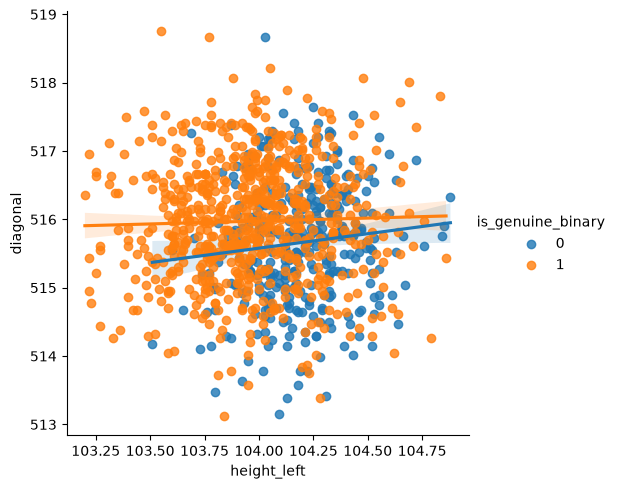

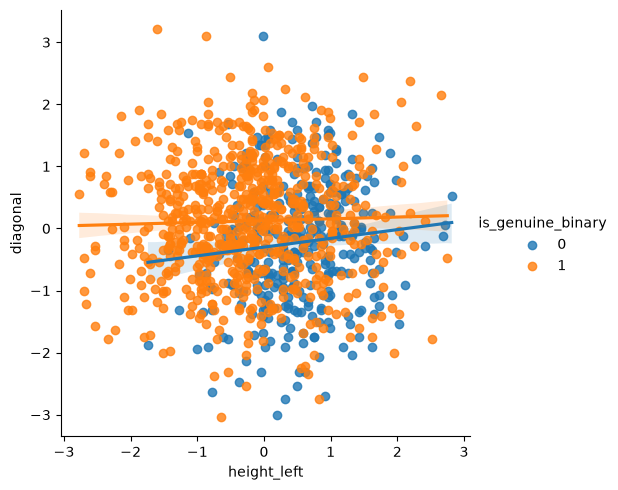

In [10]:

# Concatenate the whole train set because lmplot spects a 2D data set.
train_dataset_plot = pd.concat([X_train, y_train],axis=1)

# Display the training set
display(train_dataset_plot)
sns.lmplot(data=train_dataset_plot, x="height_left", y="diagonal", hue="is_genuine_binary")

scaler = preprocessing.StandardScaler(with_mean=True,
                        with_std=True,
                        copy=True)

train_dataset_plot[["height_left", "diagonal"]] = scaler.fit_transform(X_train[["height_left", "diagonal"]])

# Display the modified training set
display(train_dataset_plot)

sns.lmplot(data=train_dataset_plot, x="height_left", y="diagonal", hue="is_genuine_binary")


**Explanation:** 
* Use `seaborn.lmplot` ([help here](https://seaborn.pydata.org/generated/seaborn.lmplot.html)) to visualize the following two features of the training set: draw a plot where the x-axis is the `height_left`, and the y-axis is the `diagonal`, and the color of each datapoint indicates its class **[1]**.  <br><br> - Since I had all my datasets separated, I concatenated the training sets using `concat()` in order to plot them using the `lmplot()` method. <br><br>
* Standardizing the data (see *StandardScaler()* in [Help](https://scikit-learn.org/stable/modules/preprocessing.html)) is sometimes critical in machine learning (especially for distance-based methods). Show a new plot as above, but standardize the two features **[1]**. What's different? **[1]** **Why do they look similar?** **[1]** Based on your observation, what is the advantage of standardization? **[1]** <br><br> - I used `StandardScaler()` to make the predictor scales more comparable. For example, the ranges of `diagonal` and `height_left` changed from approximately **6 and 1.5 before scaling** to approximately **6 and 6 after scaling**. This makes the variables more comparable and prevents one variable from dominating distance calculations simply because of its original scale. <br><br>

# Part B: KNN [42 MARKS]

## Part B1: KNN Classifier with Standardization [9 Marks]

Let's create a KNN classifier to predict whether a bill is fake by its dimensions!


Follow these steps:

1. Standardize the training and test data (see *StandardScaler()* in [Help](https://scikit-learn.org/stable/modules/preprocessing.html)) **[1]**

2. Train a KNN Classifier using 5-fold cross-validation on the standardized training set. Sweep `k` (number of neighbours) from 1 to 600 with a step size of 1, and show a plot of the mean cross-validation accuracy vs `k`. Include standard deviation of the cross-validation accuracy as error bars on the chart **[2]**.
3.   What is the best `k`? What is the highest cross-validation accuracy? **[2]**
4. Comment on  which ranges of `k` lead to underfitted or overfitted models (hint: compare training and validation curves.). **[2]**
5. Repeat the same KNN procedure (5-fold cross-validation and a `k` sweep from 1 to 600 with a step size of 1) using the original (unstandardized) training set. Compare the best cross-validation performance with that obtained using the standardized features **[1]**, and briefly comment on the effect of standardization on KNN performance. **[2]**


**Note:** When we standardize a dataset, it matters if the data points are in our training set or test set. The training set is available for us to train a model - we can use it however we want. The test set, however, represents a subset of data that is not available for us during training. For example, the test set can represent the data that someone who bought our model would use to see how the model performs (which they are not willing to share with us).
Therefore, we cannot use the mean or standard deviation of the whole dataset to standardize it - we can only use the mean and standard deviation of the training set. When the model is ready for testing, we provide our scalers (mean and standard deviation of our training set) to the person who is going to test the model. They can scale their data (test set) with our training set's mean and standard deviation. It is unlikely that the scaled test set would exactly have a mean of zero and a standard deviation of one, but there is no such requirement for the model to perform well.

**To summarize: We fit the StandardScaler only on the training set. We transform both training and test sets with that scaler.**


*(Answer the questions above in the “Explanation” placeholder)*

In [11]:
from sklearn import neighbors
from sklearn.model_selection import cross_validate

In [12]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate

y_train_1d = y_train.values.ravel()

scaler.fit(X_train)
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

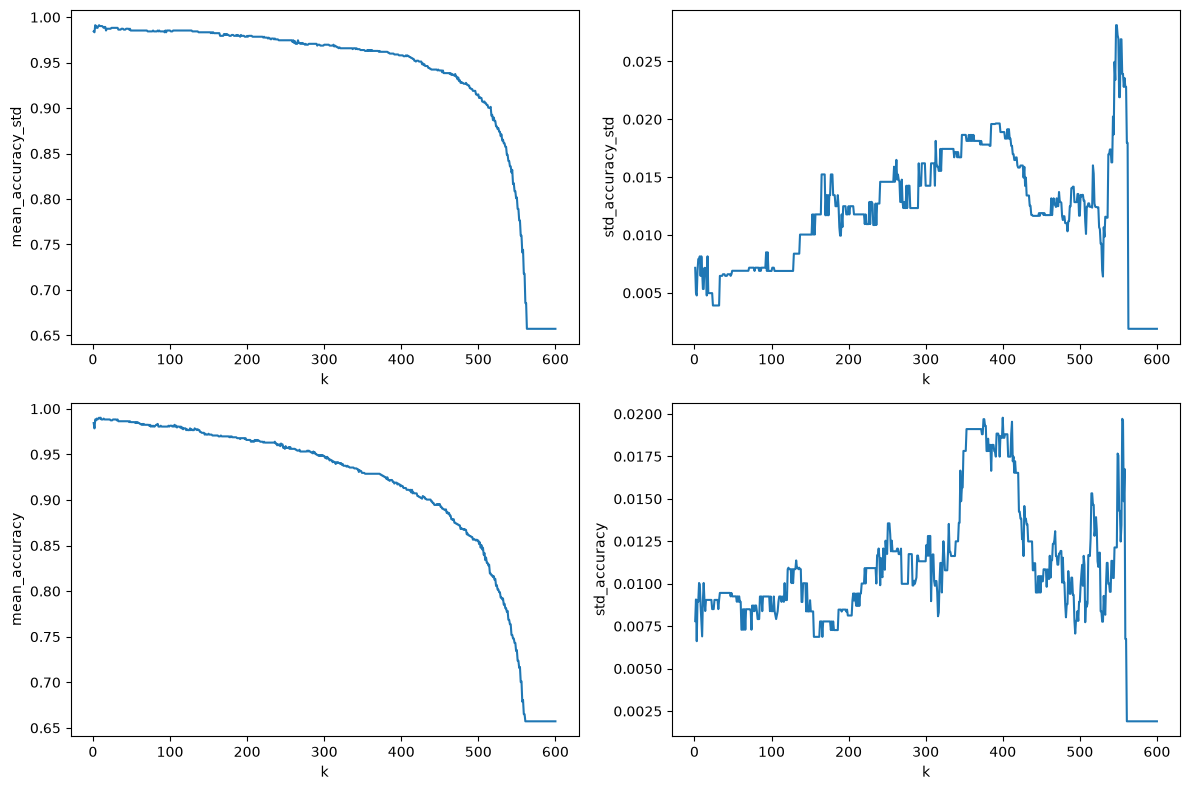

In [13]:

mean_accuracy_std = []
std_accuracy_std = []

for k in range(1, 601, 1):

    KNN_Classifier = KNeighborsClassifier(n_neighbors=k)

    cv_results = cross_validate(
        KNN_Classifier,
        X_train_std,
        y_train_1d,
        cv=5
    )

    mean_accuracy_std.append(np.mean(cv_results['test_score']))
    std_accuracy_std.append(np.std(cv_results['test_score']))

results_std = pd.DataFrame({
'k': range(1, 601),
'mean_accuracy_std': mean_accuracy_std,
'std_accuracy_std': std_accuracy_std
})

mean_accuracy = []
std_accuracy = []

for k in range(1, 601, 1):

    KNN_Classifier = KNeighborsClassifier(n_neighbors=k)

    cv_results = cross_validate(
        KNN_Classifier,
        X_train,
        y_train_1d,
        cv=5
    )

    mean_accuracy.append(np.mean(cv_results['test_score']))
    std_accuracy.append(np.std(cv_results['test_score']))

results = pd.DataFrame({
'k': range(1, 601),
'mean_accuracy': mean_accuracy,
'std_accuracy': std_accuracy
})


fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.lineplot(
    data=results_std,
    x='k',
    y='mean_accuracy_std',
    ax=axes[0, 0]
)

sns.lineplot(
    data=results_std,
    x='k',
    y='std_accuracy_std',
    ax=axes[0, 1]
)

sns.lineplot(
    data=results,
    x='k',
    y='mean_accuracy',
    ax=axes[1, 0]
)

sns.lineplot(
    data=results,
    x='k',
    y='std_accuracy',
    ax=axes[1, 1]
)

plt.tight_layout()
plt.show()


**Explanation:** (delete this parentheses and add your explanations!)

## Part B2: Forward Feature Selection [8 MARKS]

In this part, we will investigate a feature-selection approach using Forward Selection.

Forward selection is a greedy selection procedure. At each step, it augments the current feature set by including one additional feature. The selected feature is the one that gives the best model performance when added to the features already selected.

Procedure:

1. Begin by evaluating each individual feature using a KNN classifier with 5-fold cross-validation, tune `k` from 1 to 100 with a step size of 1, and select the feature that gives the highest cross-validation accuracy.
2. Add each remaining features to the current selected feature set one at a time as a candidate.
3. For each candidate addition, tune `k` over the same range used in Part B1 using 5-fold cross-validation.
4. Select the candidate feature that gives the highest mean cross-validation accuracy and add it to the selected feature set.
5. Your code records and prints the selected feature, the best mean cross-validation accuracy, and the corresponding `k`.
6. Repeat Steps 2-5 until all features have been added.


*Questions:*

* Apply forward selection to the standardized training data. **[2]**
* Plot the best mean cross-validation accuracy (y-axis) vs. the number of selected features (x-axis). **[2]**
* Plot the corresponding best k (y-axis) vs. the number of selected features (x-axis). **[2]**
* State the optimal number of selected feature subset, with the highest cross-validation accuracy, and corresponding `k`. **[2]**

*(Answer the questions above in the “Explanation” placeholder)*

In [16]:
def evaluate_candidate(X_candidate, y):

    mean_accuracy = []

    for k in range(1, 101):

        KNN_Classifier = KNeighborsClassifier(
            n_neighbors=k
        )

        cv_results = cross_validate(
            KNN_Classifier,
            X_candidate,
            y,
            cv=5
        )

        mean_accuracy.append(
            np.mean(cv_results['test_score'])
        )

    best_accuracy = max(mean_accuracy)
    best_k = np.argmax(mean_accuracy) + 1

    return int(best_k), float(best_accuracy)

In [33]:
features_selected = []
selection_results = []

X_train_std = pd.DataFrame(X_train_std, columns=X_train.columns, index=X_train.index)

features_remaining_all_features = list(X_train_std.columns)

while len(features_remaining_all_features) > 0:

    candidate_results = []

    for feature in features_remaining_all_features:

        candidate_features = features_selected + [feature]

        best_k, best_accuracy = evaluate_candidate(
            X_train_std[candidate_features],
            y_train_1d
        )

        candidate_results.append(
            [feature, best_k, best_accuracy]
        )

    best_feature_result = max(
        candidate_results,
        key=lambda x: x[2]
    )

    best_feature = best_feature_result[0]

    features_selected.append(best_feature)
    features_remaining_all_features.remove(best_feature)

    selection_results.append([
    len(features_selected),
    best_feature,
    best_feature_result[1],
    best_feature_result[2]
    ])

    print("Feature added:", best_feature)
    print("Best k:", best_feature_result[1])
    print("Mean CV accuracy:", best_feature_result[2])
    print("Selected set:", features_selected)
    print("Remaining:", features_remaining_all_features)
    

Feature added: length
Best k: 58
Mean CV accuracy: 0.9580344332855093
Selected set: ['length']
Remaining: ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up']
Feature added: margin_low
Best k: 4
Mean CV accuracy: 0.9863414634146341
Selected set: ['length', 'margin_low']
Remaining: ['diagonal', 'height_left', 'height_right', 'margin_up']
Feature added: margin_up
Best k: 6
Mean CV accuracy: 0.9902439024390244
Selected set: ['length', 'margin_low', 'margin_up']
Remaining: ['diagonal', 'height_left', 'height_right']
Feature added: height_left
Best k: 3
Mean CV accuracy: 0.9912195121951219
Selected set: ['length', 'margin_low', 'margin_up', 'height_left']
Remaining: ['diagonal', 'height_right']
Feature added: diagonal
Best k: 6
Mean CV accuracy: 0.9921951219512195
Selected set: ['length', 'margin_low', 'margin_up', 'height_left', 'diagonal']
Remaining: ['height_right']
Feature added: height_right
Best k: 8
Mean CV accuracy: 0.9912147297943568
Selected set: ['length', 'marg

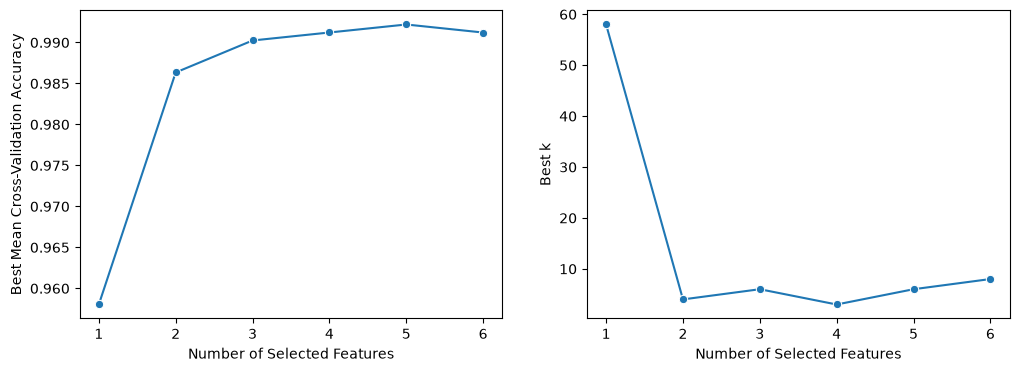

In [ ]:
selection_results_df = pd.DataFrame(
    selection_results,
    columns=[
        'n_features',
        'feature_added',
        'best_k',
        'best_accuracy'
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.lineplot(
    data=selection_results_df,
    x='n_features',
    y='best_accuracy',
    marker='o',
    ax=axes[0]
)

axes[0].set_xlabel('Number of Selected Features')
axes[0].set_ylabel('Best Mean Cross-Validation Accuracy')

sns.lineplot(
    data=selection_results_df,
    x='n_features',
    y='best_k',
    marker='o',
    ax=axes[1]
)

axes[1].set_xlabel('Number of Selected Features')
axes[1].set_ylabel('Best k')

plt.show()


plt.xlabel('Number of Selected Features')
plt.ylabel('Best k')

plt.tight_layout()
plt.show()

**Explanation:** (delete this parentheses and add your explanations!)

## Part B3: Tree-based Feature Selector Function [14 Marks]
In this part, we aim to investigate the importance of each feature on the final classification accuracy.
If we want to try every possible combination of features, we would have to test  $2^F$ different cases,  where F is the number of features, and in each case, we have to do a hyperparameter search (finding K, in KNN using cross-validation). That will take days!

To find more important features we will use a **decision tree** to compute feature importance that is a metric for our feature selection (code is provided below).

You can use [this link](https://machinelearningmastery.com/calculate-feature-importance-with-python/
) to get familiar with extracting the feature importance order of machine learning algorithms in Python.

After we identified and removed the least important feature and evaluated a new KNN model on the new set of features, if the stop conditions (see Step 7 in 8-step process described below) are not met, we need to repeat the process and remove another feature.


  
  









You can use the following piece of code to start training a decision tree classifier and obtain its feature importance order.
```
from sklearn import tree
dt = tree.DecisionTreeClassifier()
dt.fit(X_train,y_train)
importance = dt.feature_importances_
```



### The 8-step process for creating the Tree-based Feature_selector function

Design a function ( `Feature_selector`) that accepts your dataset (X_train , y_train) and a threshold as inputs and:
1. Fits a decision tree classifier on the training set.

2. Extracts the feature importance order of the decision tree model.

3. Removes the least important feature based on step 2.
4. Then, a KNN model is trained on the remaining features. The number of neighbors `k` for each KNN model should be tuned from 1 to 100 with a step size of 1 using a 5-fold cross-validation.
5. Store the best `mean cross-validation` score and the corresponding `k` (number of neighbours) value in two lists.
6. Go back to step 3 and follow all the steps until you meet the stop condition (step 7).

7. We will stop this process when (1) there is only one feature left, or (2) our cross-validation accuracy is dropped significantly compared to a model that uses all the features. In this function, we accept a threshold as an input argument. For example, if threshold=0.95 we do not continue removing features if our mean cross-validation accuracy after tuning `k` is bellow **0.95 $\times$ Full Feature cross-validation accuracy**.

8. Your function returns the list of removed features, and the corresponding mean cross-validation accuracy and `k` value when a feature was removed.


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

results_k = []
results_accuracy = []
results_featured_names = []
remaining_features = []


def Feature_selector (X_train, y_train,threshold):
    full_k, full_feature_accuracy = evaluate_candidate(X_train, y_train_1d)
    threshold_calc = threshold * full_feature_accuracy
    print(f"Threshold = 0.95 x Full Feature CV Accuracy: {threshold_calc}")
    results_df = X_train.columns
    best_accuracy = 1.0
    while len(results_df) > 1:
        dt = tree.DecisionTreeClassifier()
        dt.fit(X_train,y_train)
        importance = dt.feature_importances_
        names = dt.feature_names_in_
        #print(importance)
        #tree.plot_tree(dt)
        #print(importance.dtype)

        results_df = pd.DataFrame({"Feature":names,"Important":importance})
        #print(results_df)

        less_important_feat = results_df.loc[results_df["Important"].idxmin(),"Feature"]
        #print(less_important_feat)
        #print(less_important_feat)
        results_df = results_df.drop(results_df["Important"].idxmin())
        #print(results_df)

        X_candidate = X_train.drop(columns=[less_important_feat])

        best_k, best_accuracy  = evaluate_candidate(X_candidate,y_train)

        if best_accuracy < threshold_calc:
            break

        X_train = X_candidate

        results_featured_names.append(less_important_feat)
        results_accuracy.append(best_accuracy)
        results_k.append(best_k)
        remaining_features.append(len(X_train.columns))
        
        #print(f"Feature removed {less_important_feat}, CV Accuracy: {round(best_accuracy,3)}, k:{best_k}")

    return (results_featured_names, results_accuracy, results_k, remaining_features, full_k, full_feature_accuracy)
    
#Feature_selector(X_train_std,y_train_1d,0.95)


In [141]:

results_k = []
results_accuracy = []
results_featured_names = []
remaining_features = []

results_featured_names, results_accuracy, results_k, remaining_features, full_k, full_feature_accuracy = Feature_selector(X_train_std,y_train_1d,0.95)
remaining_features = [6] + remaining_features
results_accuracy = [full_feature_accuracy] + results_accuracy
#print(remaining_features)
#print(results_accuracy)

results_k = [full_k] + results_k

Threshold = 0.95 x Full Feature CV Accuracy: 0.9416539933046388


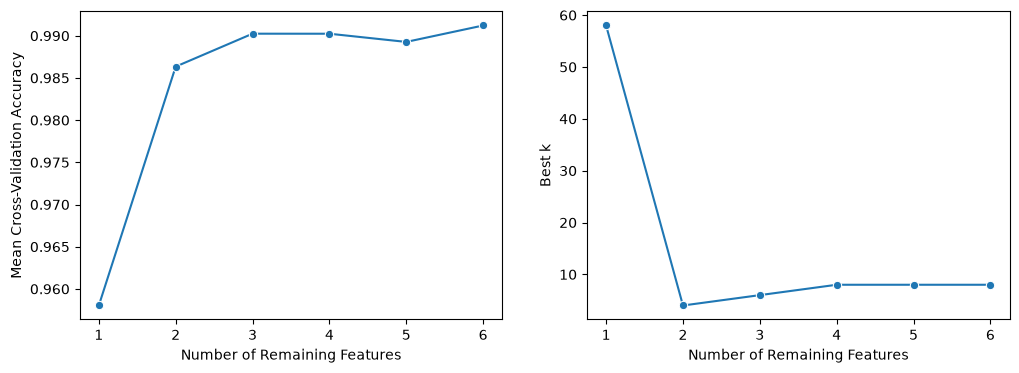

In [146]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.lineplot(
    x=remaining_features,
    y=results_accuracy,
    marker="o",
    ax=axes[0]
)

axes[0].set_xlabel("Number of Remaining Features")
axes[0].set_ylabel("Mean Cross-Validation Accuracy")

sns.lineplot(
    x=remaining_features,
    y=results_k,
    marker="o",
    ax=axes[1]
)

axes[1].set_xlabel("Number of Remaining Features")
axes[1].set_ylabel("Best k")

plt.show()

### Using the Tree-based Feature_selector function

*Questions:*

* Call your Feature_selector function on the standardized training data with a threshold of 95%. **[2]**
* Visualize your results by plotting the mean cross-validation accuracy (y axis) vs. the number of **remaining features** (x axis). This plot describes: what is the best cv score with 1 feature, 2 features, 3 features ... and all the features. **[2]**

* Plot the best value of `k` (y-axis) vs. the number of **remaining features** (x-axis). This plot explains the trend of number of neighbours (y-axis) with respect to the number of **remaining features** (x-axis).  **[2]**

* State what is the number of essential features for classification, and justify your answer.  **[2]**

* State and record the best accuracy and its corresponding  `k` value **[2]**

* Compare the tree-based feature-selection result with the forward-selection result in Part B2 in terms of classification performance and the number of retained features **[2]**. Explain the difference between the two methods.**[2]**

*(Answer the questions above in the “Explanation” placeholder)*

In [ ]:
# Add your code HERE

**Explanation:** (delete this parentheses and add your explanations!)

## Part B4: PCA-based Dimensionality Reduction [11 MARKS]

In this part, we will investigate a dimensionality-reduction approach called Principal Component Analysis (PCA).

Instead of selecting or removing individual features, PCA transforms features into a new set of uncorrelated variables called principal components. These components are ordered according to how much variance in the original data they explain.

We will vary `n_components` (number of principal components retained), then train and tune a KNN classifier on the transformed data using 5-fold cross-validation.

*Questions:*

* Apply PCA to the standardized training data [PCA Help](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html?utm_source=chatgpt.com). Sweep the number of principal components from 1 to the total number of original features. For each number of principal components, train a KNN classifier using 5-fold cross-validation and tune `k` from 1 to 100 with a step size of 1 **[2]**
* Plot the best mean cross-validation accuracy (y-axis) vs. the number of principal components (x-axis) **[2]**
* Plot the corresponding best `k` (y-axis) vs. the number of principal components (x-axis) **[2]**
* State the optimal number of principal components, the highest cross-validation accuracy, and the corresponding `k` **[3]**
* Briefly comment on whether PCA provides effective dimensionality reduction for this dataset **[2]**

*(Answer the questions above in the “Explanation” placeholder)*

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
# Add your code HERE

**Explanation:** (delete this parentheses and add your explanations!)

# Part C: Other Built-in Models & Hyperparameter Tuning **[24 MARKS]**

In this part, you will use some built-in models, and **tune their hyperparameters** to achieve high accuracy/scores.

Here we want you to **pass in the full feature**, so we won't use the Feature_selector function anymore.

The models you will be using are:

1. Decision Tree (Part C1)
2. Random Forest (Part C2)
3. Bagged Trees (Part C3)


**[24 marks]** 8 marks per model

## Part C1: Decision Tree Classifier [8 Marks]

*Questions:*
1. Train and tune a decision tree classifier on the standardized full feature training set (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) and check the example there.). Tune the two hypermarameters `max_depth` and `min_samples_split` using [RandomizedSearchCV ](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with n_iter=500, you should set the ranges of the hyperparameters as the following: **[2]**

* `'max_depth': randint(1, 10)`
* `'min_samples_split': randint(2, 50)`


  Configure RandomizedSearchCV with the following settings: **[2]**

* `cv=5`,
* `verbose=2`,
* `random_state=42`,
* `n_jobs=-1`,
* `return_train_score=True`

2. Record & print out:

* the highest  mean cross-validated accuracy/score **[2]**, and
* the values of the hyperparameters you tuned **[2]**, that achieved the highest accuracy/score. For example: *Best performance using decision tree is 0.987654321 with a max depth of 8 and a min samples split of 25*


*(Answer the questions above in the “Explanation” placeholder)*

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [ ]:
# Add your code HERE

**Explanation:** (delete this parentheses and add your explanations!)

## Part C2: Random Forests [8 Marks]

*Questions:*
1. Train and tune a Random Forest classifier on the standardized full feature training set (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) and check the example there.) Tune the two hyperparameters `n_estimators` and `max_features` using [RandomizedSearchCV ](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with n_iter=500, you should set the ranges of the hyperparameters you want to tune, set: **[2]**

* `max_features : ['sqrt', 'log2', 0.1, 0.25, 0.5]`,
* `n_estimators : randint(10, 200)`


  For RandomizedSearchCV, use: **[2]**

* `cv=5`,
* `verbose=2`,
* `random_state=42`,
* `n_jobs=-1`,

2. Record & print out:

* the highest  mean cross-validated accuracy/score **[2]**, and
* the values of the hyperparameters you tuned **[2]**, that achieved the highest accuracy/score. For example, *Best n_estimators: 60, Best Max Features: log2, Best Accuracy: 0.987654321*

*(Answer the questions above in the “Explanation” placeholder)*


In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Add your code HERE

**Explanation:** (delete this parentheses and add your explanations!)

## Part C3: Bagging (ensemble of bagged trees) [8 Marks]

*Questions:*

1. Similarly, train and tune a bagging classifier on the standardized full feature training set (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) and check the example there.). Set `max_features` to the total number of features in the dataset and use `bootstrap=True` **[2]**


   Then tune the hyperparameter `n_estimators` using 5-fold cross-validation (CV) with: **[2]**


* `n_estimators = [10, 50, 100, 200]`


2. Record & print out:

* the highest  mean cross-validated accuracy/score **[2]**, and
* the value of the hyperparameter you tuned **[2]**, that achieved the highest accuracy/score.
* i.e: *Best n_estimators (Bagged Trees): 100, Best Accuracy (Bagged Trees): 0.987654321*

*(Answer the questions above in the “Explanation” placeholder)*

In [ ]:
# Add your code HERE

**Explanation:** (delete this parentheses and add your explanations!)

# Part D: Report the accuracy of all your tuned models [4 MARKS]

Congratulations! So far you have developed 4 models, these models are:

1.   The Tuned Decision Tree (from Part C)
2.   The Tuned Random Forest (from Part C)
3.   The Tuned Bagged Trees (from Part C)
4.   Best model you developed in Part B, including the three feature selection method


*Questions:*

Either make a table or simply print out the best results for all of your models.

1 mark for each model

*(Answer the questions above in the “Explanation” placeholder)*


In [ ]:
# Add your code HERE

**Explanation:** (delete this parentheses and add your explanations!)

# Part E: Evaluation on Test Data [10 MARKS]


### Part E1: Performance measures [6]

Pick your best model (highest accuracy) and apply it to the test set you had initially set aside.

*Questions:*

Compute the following using the standardized test data (note: never standardize the y data, only standardize the x data):



1.   accuracy,
2.   precision,
3.   recall,
4.   Fall-out rate,
5.   F1 score,
6.   confusion matrix

(**1** mark for each performance metric)

*(Answer the questions above in the “Explanation” placeholder)*

In [35]:
# Add your code HERE

**Explanation:** (delete this parentheses and add your explanations!)

## Part E2: ROC and AUC [4 marks]

Using the same selected model from the previous part, plot the ROC curve **[2]** and reporting its AUC **[2]** on the test data.


In [36]:
from sklearn.metrics import roc_curve, auc

In [37]:
# Add your code HERE

**Explanation:** (delete this parentheses and add your explanations!)